# Justicia Predictiva: Predicción de Reincidencia en Libertad Condicional
## Árboles de Decisión (CART): Pre-poda, Post-poda y Análisis de Importancia de Variables

### 1. Contexto del Problema
El dataset `Parole` proviene de un escenario real de **justicia actuarial (*Actuarial Justice*)** desarrollado en colaboración entre la Universidad de Pensilvania y la Junta de Libertad Condicional de Pensilvania (PBPP). El objetivo analítico es predecir el riesgo de que un interno viole las condiciones de su libertad condicional o reincida (`Status = 1`) frente a quienes completan su período satisfactoriamente (`Status = 0`), sirviendo de soporte cuantitativo en decisiones administrativas que impactan la seguridad pública y la libertad individual.

**Enfoque metodológico:**
* **Flujo reproducible:** Partición estratificada (80/20) para preservar la proporción original sin fuga de información (*data leakage*).
* **Preprocesamiento:** Integración mediante `ColumnTransformer` (One-Hot Encoding para atributos categóricos e imputación preventiva en numéricas).
* **Auditoría de outliers:** Evaluación de consistencia mediante métodos univariados (IQR, Z-Score, MAD) y multivariados (Isolation Forest, LOF, Elliptic Envelope), determinando su conservación por representar perfiles judiciales reales.
* **Manejo del desbalance severo (11.6% positivos):** Comparación rigurosa en validación cruzada entre técnicas de remuestreo (`SMOTE`, `SMOTE-NC`, *Random Undersampling*, *Random Oversampling* y pesos balanceados).
* **Optimización y control de sobreajuste:** Pre-poda exhaustiva mediante `GridSearchCV` (max_depth, min_samples_split, min_samples_leaf) optimizando F1-score, seguida de post-poda por complejidad de costo (`ccp_alpha`) para extraer reglas de decisión compactas e interpretables.

In [3]:
# ==================================================
# Árboles de decisión - Clasificación
# Con Pre-poda, Post-poda e Importancia de Variables
# Caso: Justicia Predictiva - Predicción de reincidencia (Parole.csv)
# ==================================================
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix,
                             classification_report)
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import VarianceThreshold
from sklearn.base import clone
import matplotlib.pyplot as plt

# --- Adaptación al caso Parole: variables categóricas y clases desbalanceadas ---
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from imblearn.over_sampling import SMOTE, SMOTENC, RandomOverSampler
from imblearn.under_sampling import RandomUnderSampler
from sklearn.model_selection import cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.covariance import EllipticEnvelope
from scipy import stats
from imblearn.pipeline import Pipeline   # como sklearn.pipeline.Pipeline, pero admite SMOTE

In [4]:
# ============================================
# 1. CARGAR DATOS
# ============================================
df = pd.read_csv("Parole.csv", sep = ";")
X = df.drop(columns = ["Status"])
y = df["Status"]

class_names = ["No reincidió (0)", "Reincidió (1)"]

print(f"Observaciones: {X.shape[0]}")
print(f"Variables:     {X.shape[1]}")
print(f"Clases:        {class_names}")

Observaciones: 675
Variables:     8
Clases:        ['No reincidió (0)', 'Reincidió (1)']


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 675 entries, 0 to 674
Data columns (total 9 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Genero     675 non-null    object 
 1   Raza       675 non-null    object 
 2   Edad       675 non-null    int64  
 3   Estado     675 non-null    object 
 4   Tiempo     675 non-null    float64
 5   Sentencia  675 non-null    int64  
 6   Ofensas    675 non-null    object 
 7   Crimen     675 non-null    object 
 8   Status     675 non-null    int64  
dtypes: float64(1), int64(3), object(5)
memory usage: 47.6+ KB


,Genero,Raza,Edad,Estado,Tiempo,Sentencia,Ofensas,Crimen,Status
0,Masculino,Blanca,33,Otro,5.5,18,No,Transito,0
1,Femenino,Blanca,40,Otro,5.4,12,No,Drogas,0
2,Masculino,Negra,30,Otro,5.6,12,No,Drogas,0
3,Masculino,Blanca,22,Otro,5.7,18,No,Otro,0
4,Masculino,Negra,22,Otro,5.4,12,No,Otro,0


,count,mean,std,min,25%,50%,75%,max,IQR
Edad,675.0,34.50,10.35,18.0,25.00,34.0,42.5,67.0,17.50
Tiempo,675.0,4.20,1.23,0.0,3.25,4.4,5.2,6.0,1.95
Sentencia,675.0,13.06,3.06,1.0,12.00,12.0,15.0,18.0,3.00



Variable: Genero
           count  proportion
Genero                      
Masculino    545       80.74
Femenino     130       19.26

Variable: Raza
        count  proportion
Raza                     
Blanca    389       57.63
Negra     286       42.37

Variable: Estado
           count  proportion
Estado                      
Virginia     330       48.89
Otro         143       21.19
Kentucky     120       17.78
Louisiana     82       12.15

Variable: Ofensas
         count  proportion
Ofensas                   
Si         362       53.63
No         313       46.37

Variable: Crimen
          count  proportion
Crimen                     
Otro        315       46.67
Drogas      153       22.67
Robo        106       15.70
Transito    101       14.96

Clase 0: 597 (88.44%) | Clase 1: 78 (11.56%) | Ratio de desbalance: 7.65 a 1


/tmp/ipykernel_568/3849480902.py:34: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(class_names)
/tmp/ipykernel_568/3849480902.py:34: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(class_names)
/tmp/ipykernel_568/3849480902.py:34: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(class_names)


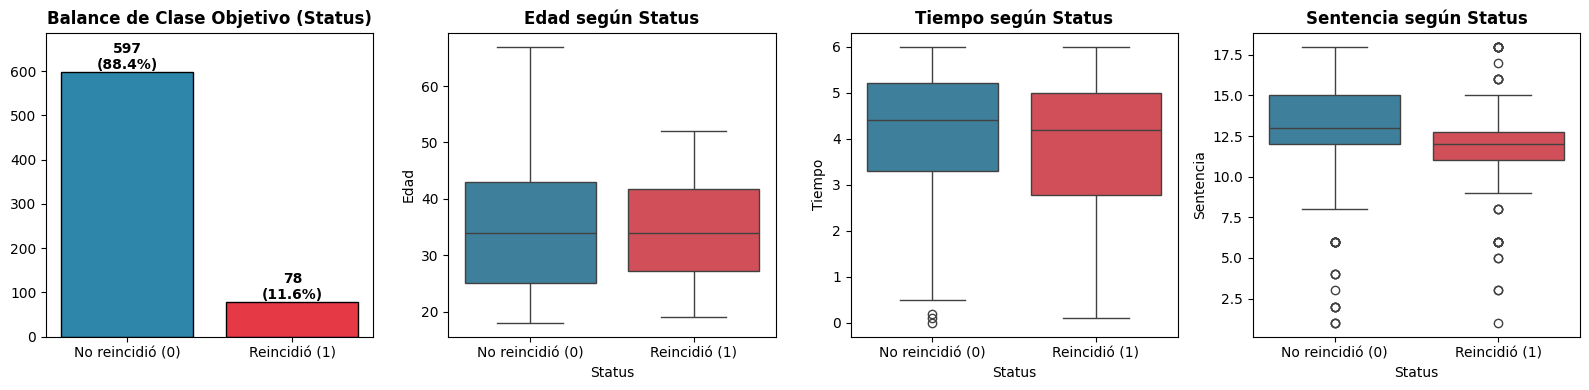

In [5]:
# ============================================
# 1.1 ANÁLISIS DESCRIPTIVO DE LOS DATOS (aporte propio)
# ============================================
vars_numericas   = ["Edad", "Tiempo", "Sentencia"]
vars_categoricas = ["Genero", "Raza", "Estado", "Ofensas", "Crimen"]

# Estructura: tipos de datos, valores nulos y primeras observaciones
df.info()
display(df.head())

# Variables cuantitativas: resumen estadístico + IQR
stats_num = df[vars_numericas].describe().T
stats_num["IQR"] = stats_num["75%"] - stats_num["25%"]
display(stats_num.round(2))

# Variables categóricas: frecuencia y porcentaje
for col in vars_categoricas:
    print(f"\nVariable: {col}\n", pd.concat([df[col].value_counts(), (df[col].value_counts(normalize = True) * 100).round(2)], axis = 1), sep = "")

# Variable objetivo: balance de clases
frec = y.value_counts().sort_index()
print(f"\nClase 0: {frec[0]} ({frec[0] / len(y):.2%}) | Clase 1: {frec[1]} ({frec[1] / len(y):.2%}) | Ratio de desbalance: {frec[0] / frec[1]:.2f} a 1")

# Gráficos: balance de la clase objetivo + boxplots de las cuantitativas según Status
fig, axes = plt.subplots(1, 4, figsize = (16, 4))
bars = axes[0].bar(class_names, frec.values, color = ['#2E86AB', '#E63946'], edgecolor = 'black')
axes[0].bar_label(bars, labels = [f"{v}\n({v / len(y):.1%})" for v in frec.values], fontweight = 'bold')
axes[0].set_title('Balance de Clase Objetivo (Status)', fontweight = 'bold')
axes[0].set_ylim(0, frec.max() * 1.15)

for ax, col in zip(axes[1:], vars_numericas):
    sns.boxplot(data = df, x = 'Status', y = col, hue = 'Status', palette = ['#2E86AB', '#E63946'], legend = False, ax = ax)
    ax.set_title(f'{col} según Status', fontweight = 'bold')
    ax.set_xticklabels(class_names)

plt.tight_layout()
plt.show()

#### Hallazgos del análisis descriptivo
- **Calidad de los datos:** 675 observaciones, 8 variables predictoras y la variable objetivo, con **0 valores nulos** en todas las columnas.
- **Variable objetivo desbalanceada:** solo 78 internos reincidieron (**11.56%**) frente a 597 que no (88.44%), un ratio de **7.65 a 1**. Un modelo que prediga siempre "No reincidió" alcanzaría ≈ 88% de *accuracy* sin detectar a ningún reincidente, por lo que la *accuracy* no es una métrica adecuada: se optimiza **F1**, se reporta el **Recall** de la clase "Reincidió" y el desbalance se trata con `SMOTE` solo en entrenamiento.
- **Variables cuantitativas:** `Edad` (mediana 34, rango 18–67), `Tiempo` (mediana 4.4, rango 0–6) y `Sentencia` (mediana 12, rango 1–18). Los boxplots según `Status` muestran distribuciones muy parecidas en ambos grupos (medianas casi iguales), lo que anticipa un problema de clasificación difícil, sin una frontera evidente en una sola variable.
- **Variables categóricas:** predominan los hombres (80.7%) y la raza blanca (57.6%); Virginia concentra el 48.9% de los casos, el 53.6% tiene ofensas múltiples y el tipo de crimen más frecuente es "Otro" (46.7%).

### 2. Justificación de la Partición Train / Test
Siguiendo el script de clase (`Arboles - Python.ipynb`), se realiza una partición **Hold-Out del 80% para Entrenamiento (`Train`) y 20% para Prueba (`Test`)** con muestreo estratificado (`stratify = y`) y semilla fija (`random_state = 42`), **antes de aplicar cualquier transformación o balanceo**, para evitar *Data Leakage* (fuga de información).

**¿Por qué 80/20 estratificado es adecuado en este caso?**
1. **Tamaño muestral moderado ($n = 675$) y escasez de la clase positiva ($n_1 = 78$):** una partición 80/20 retiene **540 observaciones en `Train` (con 62 casos positivos)**, de modo que la validación cruzada interna (5-Fold CV) dispone de ≈ 12 casos reales de reincidencia por *fold* de validación, y reserva **135 observaciones en `Test` (con 16 casos positivos)** para una evaluación final independiente.
2. **Conservación de la distribución real (`stratify = y`):** garantiza que `Train` y `Test` mantengan la proporción original de ≈ 88.5% (Clase 0) y ≈ 11.5% (Clase 1).

In [6]:
# ============================================
# 2. TRAIN / TEST SPLIT
# ============================================
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size = 0.2, random_state = 42, stratify = y
)
print(f"\nTrain: {X_train.shape[0]} observaciones | Test: {X_test.shape[0]} observaciones")


Train: 540 observaciones | Test: 135 observaciones


### 2.1 Detección de outliers (script de clase `Deteccion_de_Outliers`)
Se aplican los métodos **univariados** (Z-Score, IQR, MAD) y **multivariados** (Isolation Forest, LOF, Elliptic Envelope)
sobre las variables numéricas del **entrenamiento** (`Edad`, `Tiempo`, `Sentencia`).

In [7]:
# ============================================
# 2.1 DETECCIÓN DE OUTLIERS (solo TRAIN)
# ============================================
def get_outliers_zscore(X, threshold = 3):
    z_scores = np.abs(stats.zscore(X))
    return np.any(z_scores > threshold, axis = 1)

def get_outliers_iqr(X, multiplier = 1.5):
    outlier_mask = np.zeros(X.shape[0], dtype = bool)
    for col in range(X.shape[1]):
        q1, q3 = np.percentile(X[:, col], 25), np.percentile(X[:, col], 75)
        iqr = q3 - q1
        outlier_mask |= (X[:, col] < q1 - multiplier * iqr) | (X[:, col] > q3 + multiplier * iqr)
    return outlier_mask

def get_outliers_mad(X, threshold = 3.5):
    outlier_mask = np.zeros(X.shape[0], dtype = bool)
    for col in range(X.shape[1]):
        median = np.median(X[:, col]); mad = np.median(np.abs(X[:, col] - median))
        if mad > 0:
            outlier_mask |= np.abs(0.6745 * (X[:, col] - median) / mad) > threshold
    return outlier_mask

def get_outliers_iforest(X, contamination = 0.05):
    X_scaled = StandardScaler().fit_transform(X)
    return IsolationForest(contamination = contamination, random_state = 42).fit_predict(X_scaled) == -1

def get_outliers_lof(X, contamination = 0.05):
    X_scaled = StandardScaler().fit_transform(X)
    return LocalOutlierFactor(contamination = contamination).fit_predict(X_scaled) == -1

def get_outliers_elliptic(X, contamination = 0.05):
    X_scaled = StandardScaler().fit_transform(X)
    return EllipticEnvelope(contamination = contamination, random_state = 42).fit_predict(X_scaled) == -1

X_num_train = X_train[vars_numericas].values
mascaras = {
    "Z-Score":  get_outliers_zscore(X_num_train),
    "IQR":      get_outliers_iqr(X_num_train),
    "MAD":      get_outliers_mad(X_num_train),
    "IForest":  get_outliers_iforest(X_num_train),
    "LOF":      get_outliers_lof(X_num_train),
    "Elliptic": get_outliers_elliptic(X_num_train),
}
mascaras["Todos Uni"]   = mascaras["Z-Score"] & mascaras["IQR"] & mascaras["MAD"]
mascaras["Todos Multi"] = mascaras["IForest"] & mascaras["LOF"] & mascaras["Elliptic"]

tabla_outliers = pd.DataFrame({"N° outliers": {k: int(v.sum()) for k, v in mascaras.items()}})
tabla_outliers["% del train"] = (tabla_outliers["N° outliers"] / len(X_train) * 100).round(1)
print(tabla_outliers)

print("\nOutliers por variable (IQR):")
for j, col in enumerate(vars_numericas):
    print(f"  {col:10s}: {int(get_outliers_iqr(X_num_train[:, [j]]).sum())}")

             N° outliers  % del train
Z-Score               15          2.8
IQR                   31          5.7
MAD                   89         16.5
IForest               27          5.0
LOF                   27          5.0
Elliptic              27          5.0
Todos Uni             12          2.2
Todos Multi            3          0.6

Outliers por variable (IQR):
  Edad      : 0
  Tiempo    : 4
  Sentencia : 27


**Decisión: los outliers se mantienen.** CART divide por **orden** (`x ≤ s`), así que un valor extremo no distorsiona
los cortes como lo haría en un modelo basado en distancias o medias. Además, los valores detectados (por ejemplo `Tiempo`
cercano a 0 o `Sentencia` = 1 mes) son plausibles en el contexto judicial, y con solo 78 reincidentes eliminar observaciones
reduciría aún más la información de la clase minoritaria.

### 3. Diseño del Preprocesamiento y del Pipeline (CART + SMOTE)
El `Pipeline` del script de clase (`SimpleImputer` → `DecisionTreeClassifier`) se adapta al caso Parole con las siguientes decisiones técnicas:

1. **Imputación preventiva (`SimpleImputer`, mediana):** se conserva el paso del script de clase sobre las variables numéricas. El análisis descriptivo mostró **0 valores nulos**, por lo que en estos datos no modifica nada, pero hace que el `Pipeline` sea robusto ante datos nuevos con valores faltantes.
2. **Sin escalado de las numéricas:** CART busca puntos de corte $x_a \le s$ que minimicen la impureza (Gini o Entropía) y solo depende del **orden relativo** de los valores, no de distancias; por eso es invariante a transformaciones monótonas y no requiere `StandardScaler`. Conservar las unidades originales permite leer directamente los umbrales del árbol. *(`SMOTE` sí usa distancias entre vecinos para generar los puntos sintéticos, pero solo actúa sobre el entrenamiento y no cambia la naturaleza del árbol.)*
3. **`OneHotEncoder` para las categóricas:** a diferencia de ID3/C4.5, que ramifican de forma nativa por cada categoría (con *Ganancia de Información* y *Gain Ratio*, respectivamente), `DecisionTreeClassifier` de `scikit-learn` implementa **CART**, que solo realiza **particiones binarias sobre variables numéricas**. Por ello las 5 categóricas se codifican con `OneHotEncoder(drop = "if_binary", ...)`: las binarias (`Genero`, `Raza`, `Ofensas`) generan una sola columna 0/1 y las politómicas (`Estado`, `Crimen`) se expanden en variables *dummy*.
4. **Balanceo solo en entrenamiento, dentro del `Pipeline`:** con solo 11.56% de casos positivos, un árbol estándar tiende a favorecer la clase mayoritaria y a ocultar falsos negativos. Al ubicar el sampler dentro del `Pipeline` de `imblearn`, el balanceo se aplica **dentro de cada *fold* de entrenamiento** de `GridSearchCV` y nunca sobre el *fold* de validación ni sobre `X_test`.
5. **Comparación de técnicas de balanceo (script de clase `Balance_de_Clases`):** en vez de fijar SMOTE de antemano, se comparan
   *sin balanceo*, *Random Undersampling*, *Random Oversampling*, *SMOTE*, *SMOTE-NC* y *pesos de clase* con validación cruzada.
   **Ojo con SMOTE sobre One-Hot:** SMOTE interpola entre vecinos y sobre columnas dummy genera valores imposibles
   (por ejemplo `Ofensas_Si = 0.37`). **SMOTE-NC** (*Nominal and Continuous*) interpola solo las numéricas y asigna a las
   categóricas la categoría más frecuente entre los vecinos, por eso se aplica **antes** del One-Hot.

In [8]:

# ============================================
# 3. PIPELINE
# ============================================
# Preprocesamiento: imputación (numéricas) + OneHot (categóricas)
preprocesador = ColumnTransformer([
    ("num", SimpleImputer(strategy = "median"), vars_numericas),
    ("cat", OneHotEncoder(drop = "if_binary", sparse_output = False, handle_unknown = "ignore"), vars_categoricas)
], verbose_feature_names_out = False)

# ============================================
# 3.1 COMPARACIÓN DE TÉCNICAS DE BALANCEO (script de clase Balance_de_Clases)
# ============================================
idx_cat = [X.columns.get_loc(c) for c in vars_categoricas]   # posiciones de las categóricas (para SMOTE-NC)

# (nombre, sampler, ¿va antes del OneHot?, class_weight)
tecnicas = {
    "Sin balanceo":         (None, False, None),
    "Random Undersampling": (RandomUnderSampler(random_state = 42), True, None),
    "Random Oversampling":  (RandomOverSampler(random_state = 42), True, None),
    "SMOTE (sobre OneHot)": (SMOTE(random_state = 42), False, None),
    "SMOTE-NC":             (SMOTENC(categorical_features = idx_cat, random_state = 42), True, None),
    "Pesos 'balanced'":     (None, False, "balanced"),
}

def armar_pipeline(sampler, antes, class_weight, tree_params = None):
    pasos = []
    if sampler is not None and antes:
        pasos.append(("balanceo", clone(sampler)))
    pasos.append(("preprocesador", clone(preprocesador)))
    if sampler is not None and not antes:
        pasos.append(("balanceo", clone(sampler)))
    pasos.append(("tree", DecisionTreeClassifier(random_state = 42, class_weight = class_weight, **(tree_params or {}))))
    return Pipeline(pasos)

# Árbol de referencia (profundidad 3) para comparar las técnicas en igualdad de condiciones
scoring_metrics = ["accuracy", "precision", "recall", "f1", "roc_auc"]
res_bal = {}
for nombre, (s, antes, cw) in tecnicas.items():
    r = cross_validate(armar_pipeline(s, antes, cw, {"max_depth": 3}), X_train, y_train,
                       cv = 5, scoring = scoring_metrics)
    res_bal[nombre] = {m: r[f"test_{m}"].mean() for m in scoring_metrics}
    res_bal[nombre]["sd f1"] = r["test_f1"].std()

tabla_bal = pd.DataFrame(res_bal).T.sort_values("f1", ascending = False).round(4)
print(tabla_bal)

MEJOR_BALANCEO = tabla_bal.index[0]
SAMPLER, ANTES, CW = tecnicas[MEJOR_BALANCEO]
print(f"\n>> Técnica elegida (mayor F1 en CV): {MEJOR_BALANCEO}")

# Pipeline final con la técnica ganadora
pipe = armar_pipeline(SAMPLER, ANTES, CW)
pipe


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


                      accuracy  precision  recall      f1  roc_auc   sd f1
SMOTE (sobre OneHot)    0.8185     0.3658  0.6603  0.4633   0.8222  0.0788
Random Undersampling    0.7870     0.3139  0.6744  0.4200   0.7644  0.0405
SMOTE-NC                0.7926     0.3105  0.5667  0.3770   0.7713  0.0626
Random Oversampling     0.7463     0.2722  0.6244  0.3697   0.7341  0.0454
Pesos 'balanced'        0.6704     0.2325  0.7397  0.3465   0.7783  0.0386
Sin balanceo            0.8778     0.3905  0.1474  0.2026   0.7512  0.1043

>> Técnica elegida (mayor F1 en CV): SMOTE (sobre OneHot)


Pipeline(steps=[('preprocesador',
                 ColumnTransformer(transformers=[('num',
                                                  SimpleImputer(strategy='median'),
                                                  ['Edad', 'Tiempo',
                                                   'Sentencia']),
                                                 ('cat',
                                                  OneHotEncoder(drop='if_binary',
                                                                handle_unknown='ignore',
                                                                sparse_output=False),
                                                  ['Genero', 'Raza', 'Estado',
                                                   'Ofensas', 'Crimen'])],
                                   verbose_feature_names_out=False)),
                ('balanceo', SMOTE(random_state=42)),
                ('tree', DecisionTreeClassifier(random_state=42))])

### 4. Pre-poda: búsqueda de hiperparámetros con `GridSearchCV`
Con validación cruzada de 5 folds se busca la mejor combinación de `criterion` (Gini vs. Entropía), `max_depth`, `min_samples_split` y `min_samples_leaf`. Estos hiperparámetros **detienen el crecimiento** del árbol antes de que memorice el entrenamiento (pre-poda). Se optimiza **F1** (métrica de la clase positiva "Reincidió"), porque equilibra *Precision* y *Recall* ante el desbalance.

In [9]:
# ============================================
# 4. GRID SEARCH (PRE-PODA)
# ============================================
param_grid = {
    "tree__criterion":         ["gini", "entropy"],
    "tree__max_depth":         [2, 3, 5, 7, 10, None],
    "tree__min_samples_split": [2, 5, 10],
    "tree__min_samples_leaf":  [1, 2, 5]
}

grid = GridSearchCV(
    pipe, param_grid,
    cv = 5, scoring = "f1", n_jobs = -1, verbose = 1,
)
grid.fit(X_train, y_train)

print("\nMejores parámetros (Pre-poda):", grid.best_params_)
print("Mejor F1 CV (Pre-poda):", round(grid.best_score_, 4))

best_prepoda  = grid.best_estimator_
arbol_prepoda = best_prepoda.named_steps["tree"]

# Estructura del árbol pre-podado
n_nodos_antes     = arbol_prepoda.tree_.node_count
n_hojas_antes     = arbol_prepoda.get_n_leaves()
profundidad_antes = arbol_prepoda.get_depth()

print(f"Estructura:  Nodos = {n_nodos_antes} | Hojas = {n_hojas_antes} | Prof. = {profundidad_antes}")

Fitting 5 folds for each of 108 candidates, totalling 540 fits

Mejores parámetros (Pre-poda): {'tree__criterion': 'gini', 'tree__max_depth': 3, 'tree__min_samples_leaf': 1, 'tree__min_samples_split': 2}
Mejor F1 CV (Pre-poda): 0.4633
Estructura:  Nodos = 15 | Hojas = 8 | Prof. = 3


### 5. Post-poda: `ccp_alpha` (*Minimal Cost-Complexity Pruning*)
A diferencia de la pre-poda, que detiene el crecimiento de forma anticipada, la **post-poda** deja crecer el árbol y luego recorta de abajo hacia arriba las ramas que no aportan suficiente poder predictivo. El parámetro $\alpha \ge 0$ (`ccp_alpha`) penaliza la complejidad en la función de costo de CART:

$$\text{Costo}_{\alpha}(T) = \text{Error}(T) + \alpha |T|$$

donde $|T|$ es el número de hojas del árbol. Para cada rama se calcula su **debilidad** (*effective alpha*):

$$\text{Debilidad} = \frac{\text{Error}(T_{\text{podado}}) - \text{Error}(T_{\text{rama}})}{|T_{\text{rama}}| - |T_{\text{podado}}|}$$

Si $\text{Debilidad} < \alpha$ la rama se poda (se colapsa en una hoja); si $\text{Debilidad} \ge \alpha$ se conserva. Con $\alpha = 0$ no hay penalización (riesgo de sobreajuste) y a mayor $\alpha$ el árbol resultante es más pequeño.

Como en el script de clase, los valores candidatos de $\alpha$ no se inventan: se obtienen con `cost_complexity_pruning_path` sobre el árbol ganador de la pre-poda y luego se elige el mejor mediante validación cruzada. **Adaptación al caso Parole:** el árbol se entrena con datos *ya preprocesados y balanceados con `SMOTE`*, por lo que el *path* de poda se calcula sobre esos mismos datos (`X_train_res`, `y_train_res`) para que los valores de $\alpha$ correspondan a la escala del árbol que realmente se entrenó.

In [10]:
# ============================================
# 5. POST-PODA (ccp_alpha)
# ============================================
# 1. Reproducir los datos con los que se entrenó el árbol (preprocesados y balanceados, si corresponde)
#    para que el path de poda se calcule sobre esos mismos datos
prep_ = best_prepoda.named_steps["preprocesador"]
if SAMPLER is None:                                   # sin balanceo o pesos de clase
    X_train_res, y_train_res = prep_.transform(X_train), y_train
elif ANTES:                                           # Under / Over / SMOTE-NC: antes del OneHot
    X_bal, y_train_res = clone(SAMPLER).fit_resample(X_train, y_train)
    X_train_res = prep_.transform(X_bal)
else:                                                 # SMOTE: después del OneHot
    X_train_res, y_train_res = clone(SAMPLER).fit_resample(prep_.transform(X_train), y_train)

# 2. Path de poda sobre el árbol ganador
arbol      = best_prepoda.named_steps["tree"]
path       = arbol.cost_complexity_pruning_path(X_train_res, y_train_res)
ccp_alphas = path.ccp_alphas[:-1]

print(f"Valores de ccp_alpha a evaluar: {len(ccp_alphas)}")
print(f"Rango: {ccp_alphas.min():.6f} a {ccp_alphas.max():.6f}")

# 3. Buscar el mejor ccp_alpha con CV
grid_post = GridSearchCV(
    clone(best_prepoda),
    param_grid = {"tree__ccp_alpha": ccp_alphas},
    cv = 5, scoring = "f1", n_jobs = -1
).fit(X_train, y_train)

best_postpoda  = grid_post.best_estimator_
arbol_postpoda = best_postpoda.named_steps["tree"]

mejor_alpha       = grid_post.best_params_["tree__ccp_alpha"]
mejor_f1_postpoda = grid_post.best_score_

print(f"\nMejor ccp_alpha:        {mejor_alpha:.6f}")
print(f"Mejor F1 CV (Post-poda): {mejor_f1_postpoda:.4f}")

# Estructura del árbol post-podado
nodos_post = arbol_postpoda.tree_.node_count
hojas_post = arbol_postpoda.get_n_leaves()
prof_post  = arbol_postpoda.get_depth()

print(f"Estructura:  Nodos = {nodos_post} | Hojas = {hojas_post} | Prof. = {prof_post}")

Valores de ccp_alpha a evaluar: 7
Rango: 0.000000 a 0.110381

Mejor ccp_alpha:        0.023625
Mejor F1 CV (Post-poda): 0.4723
Estructura:  Nodos = 5 | Hojas = 3 | Prof. = 2


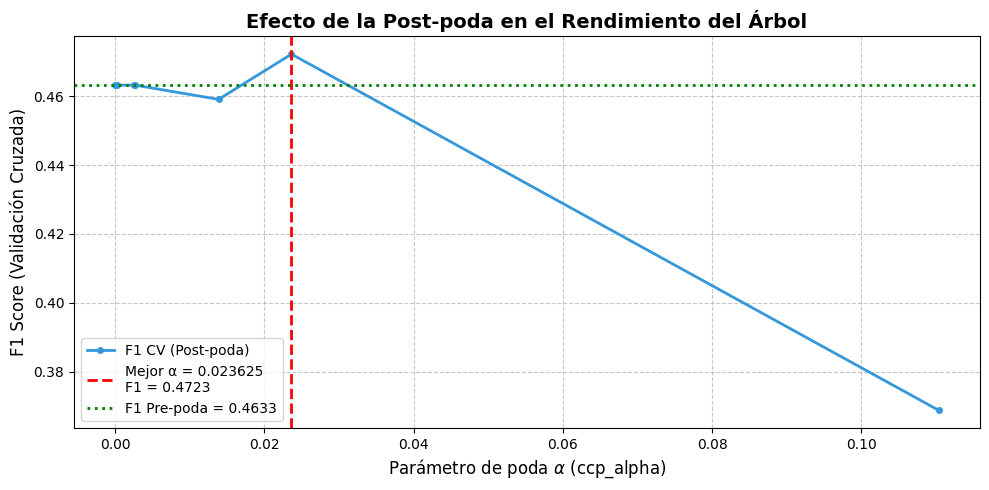

In [11]:
# ============================================
# 6. GRÁFICO: F1 vs ccp_alpha
# ============================================
alphas_validos     = grid_post.cv_results_["param_tree__ccp_alpha"].data
f1_scores_postpoda = grid_post.cv_results_["mean_test_score"]

plt.figure(figsize=(10, 5))
plt.plot(alphas_validos, f1_scores_postpoda,
         marker='o', color='#3498db', linewidth=2, markersize=4,
         label='F1 CV (Post-poda)')

plt.axvline(x=mejor_alpha, color='red', linestyle='--', linewidth=2,
            label=f'Mejor α = {mejor_alpha:.6f}\nF1 = {mejor_f1_postpoda:.4f}')
plt.axhline(y=grid.best_score_, color='green', linestyle=':', linewidth=2,
            label=f'F1 Pre-poda = {grid.best_score_:.4f}')

plt.xlabel(r'Parámetro de poda $\alpha$ (ccp_alpha)', fontsize=12)
plt.ylabel('F1 Score (Validación Cruzada)', fontsize=12)
plt.title('Efecto de la Post-poda en el Rendimiento del Árbol',
          fontsize=14, fontweight='bold')
plt.legend(loc='best', fontsize=10)
plt.grid(linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

In [12]:
# ============================================
# 7. EVALUACIÓN EN TEST
# ============================================
modelo_final = best_postpoda   # opciones: best_prepoda, best_postpoda

y_pred = modelo_final.predict(X_test)
y_prob = modelo_final.predict_proba(X_test)[:, 1]

# Reporte completo (con target_names en ambos)
reporte = classification_report(
    y_test, y_pred,
    target_names=class_names,
    output_dict=True
)
print(classification_report(y_test, y_pred, target_names=class_names))

# AUC-ROC
print(f"AUC-ROC: {roc_auc_score(y_test, y_prob):.4f}")

# Matriz de confusión con etiquetas
cm = confusion_matrix(y_test, y_pred)
cm_df = pd.DataFrame(
    cm,
    index   = [f"Real {c}" for c in class_names],
    columns = [f"Pred {c}" for c in class_names]
)
print("\nMatriz de confusión:\n", cm_df)

# Enfocado en clase 'Reincidió' (clase 1)
print(f"\n--- Enfocado en clase '{class_names[1]}' ---")
print(f"Recall:    {reporte[class_names[1]]['recall']:.4f}")
print(f"Precision: {reporte[class_names[1]]['precision']:.4f}")
print(f"F1:        {reporte[class_names[1]]['f1-score']:.4f}")

                  precision    recall  f1-score   support

No reincidió (0)       0.94      0.91      0.92       119
   Reincidió (1)       0.45      0.56      0.50        16

        accuracy                           0.87       135
       macro avg       0.69      0.74      0.71       135
    weighted avg       0.88      0.87      0.87       135

AUC-ROC: 0.7941

Matriz de confusión:
                        Pred No reincidió (0)  Pred Reincidió (1)
Real No reincidió (0)                    108                  11
Real Reincidió (1)                         7                   9

--- Enfocado en clase 'Reincidió (1)' ---
Recall:    0.5625
Precision: 0.4500
F1:        0.5000


In [13]:
# ============================================
# 8. IMPORTANCIA DE VARIABLES
# ============================================
arbol_final = modelo_final.named_steps["tree"]   # ← extraer del Pipeline
feature_names = list(modelo_final.named_steps["preprocesador"].get_feature_names_out())   # nombres tras el OneHot

df_importancias = (
    pd.DataFrame({
        'Variable':    feature_names,
        'Importancia': arbol_final.feature_importances_
    })
    .sort_values('Importancia', ascending=False)
    .reset_index(drop=True)
)

# Solo variables que el árbol realmente usó
df_imp_activas = df_importancias[df_importancias['Importancia'] > 0].copy()
df_imp_activas['Acumulado'] = df_imp_activas['Importancia'].cumsum()

print(f"Variables usadas: {len(df_imp_activas)} de {len(feature_names)}")
print(df_imp_activas.head(15).round(4).to_string(index=False))

Variables usadas: 2 de 14
       Variable  Importancia  Acumulado
Estado_Virginia       0.5921     0.5921
     Ofensas_Si       0.4079     1.0000


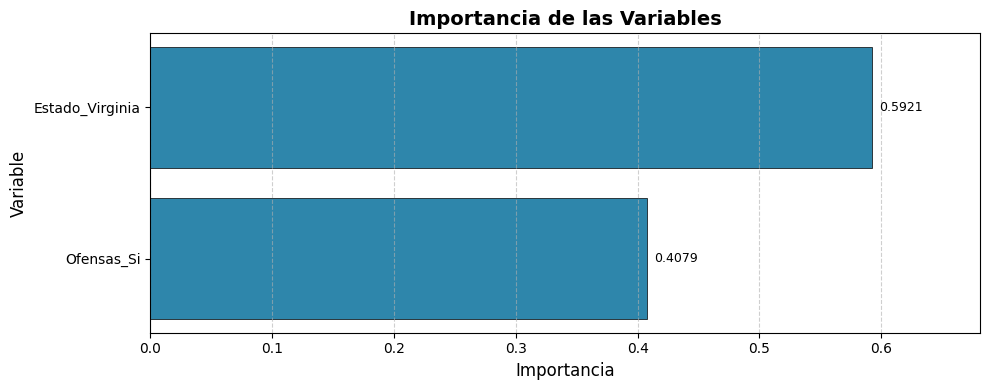

In [14]:
# ============================================
# 9. GRÁFICO - IMPORTANCIA DE VARIABLES
# ============================================
df_plot = df_imp_activas.iloc[::-1]   # invertir para que la más importante quede arriba

plt.figure(figsize=(10, max(4, 0.4 * len(df_plot))))   # altura dinámica según nº de variables
bars = plt.barh(df_plot['Variable'], df_plot['Importancia'],
                color='#2E86AB', edgecolor='black', linewidth=0.5)

# Etiquetas con el valor al final de cada barra
for i, v in enumerate(df_plot['Importancia']):
    plt.text(v + df_plot['Importancia'].max() * 0.01, i,
             f"{v:.4f}", va='center', fontsize=9)

plt.xlabel('Importancia', fontsize=12)
plt.ylabel('Variable', fontsize=12)
plt.title(f'Importancia de las Variables',
          fontsize=14, fontweight='bold')
plt.grid(axis='x', linestyle='--', alpha=0.6)
plt.xlim(0, df_plot['Importancia'].max() * 1.15)   # margen para las etiquetas
plt.tight_layout()
plt.show()

### 10. Árbol final
Los valores `samples` y `value` de cada nodo se calculan sobre el conjunto de entrenamiento **ya balanceado** (con la técnica elegida en la sección 3.1): por eso la raíz muestra la misma cantidad de casos de cada clase y un total mayor que las 540 observaciones originales. No son conteos de internos reales, sino de la muestra con la que se construyó el árbol.

Número total de nodos:  5
Número de hojas:        3
Profundidad máxima:     2

Reducción por post-poda (vs árbol pre-podado):
  Nodos:  15 → 5  (Δ = 10)
  Hojas:  8 → 3  (Δ = 5)
  Prof.:  3 → 2


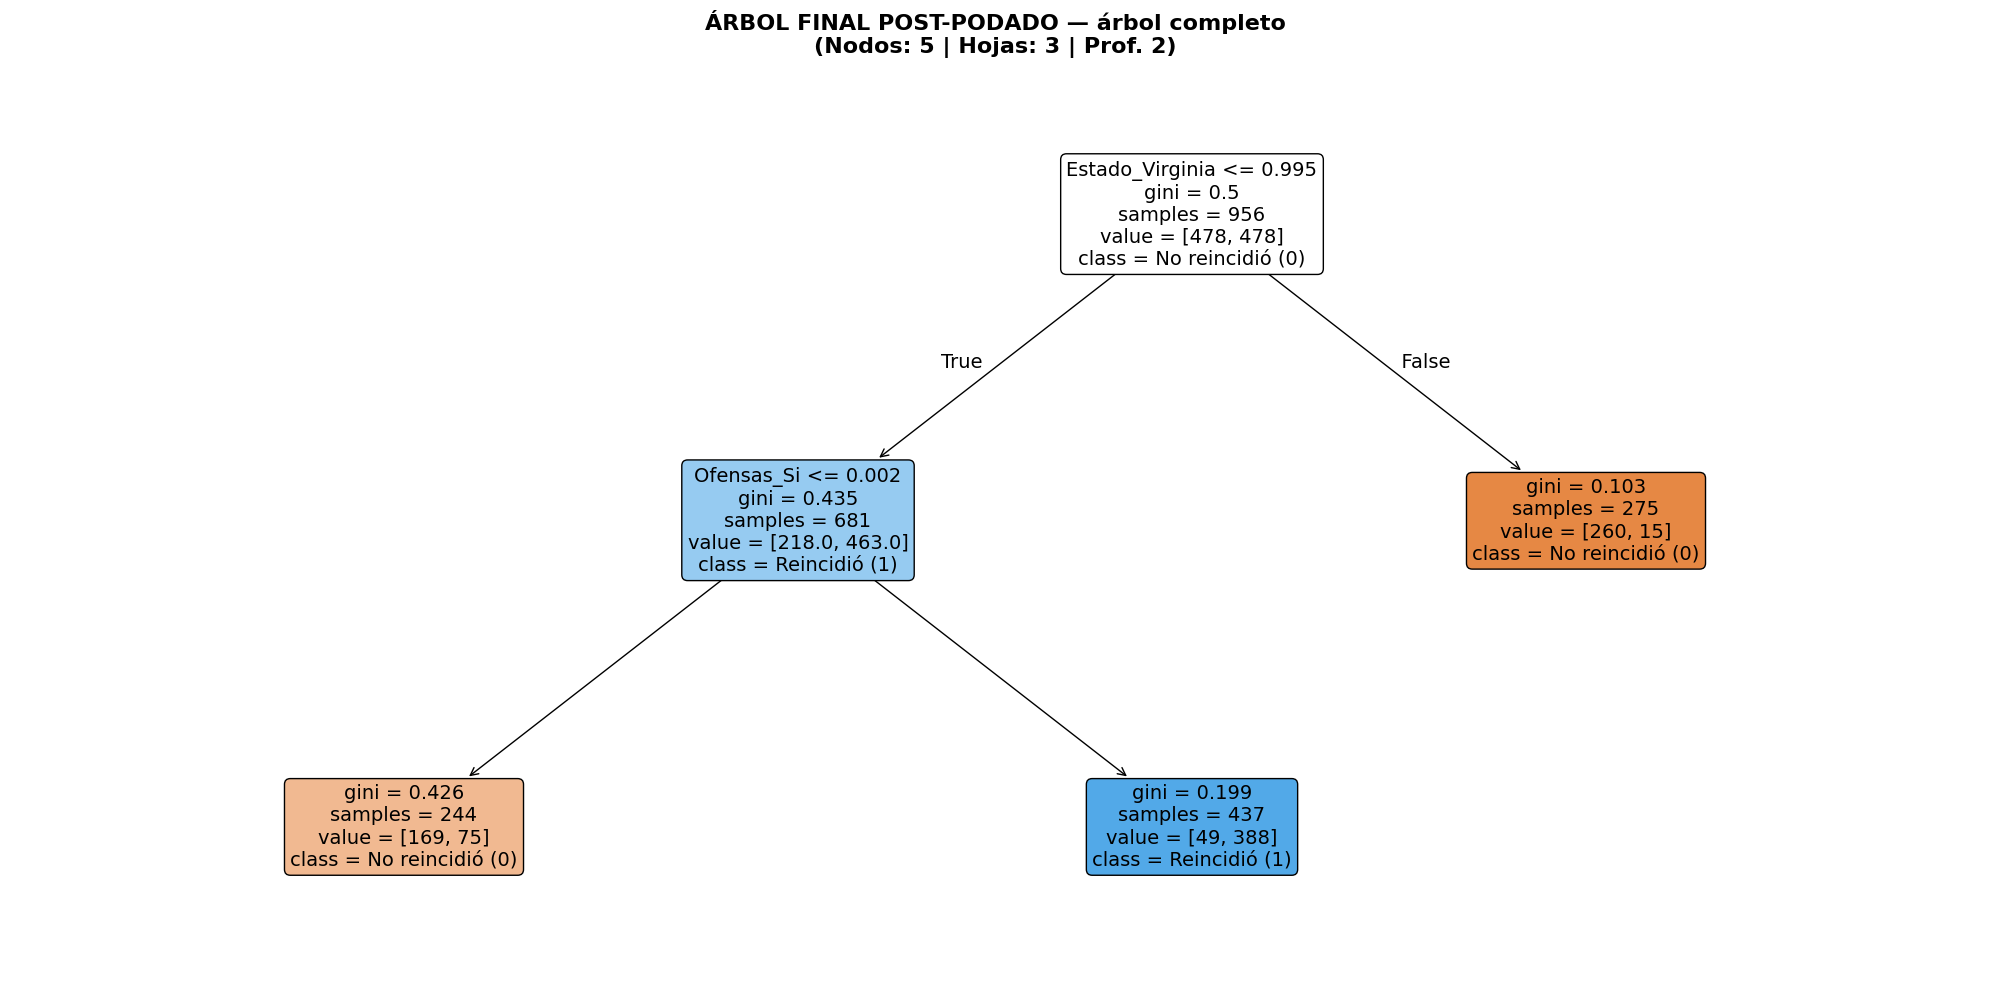

|--- Estado_Virginia <= 1.00
|   |--- Ofensas_Si <= 0.00
|   |   |--- weights: [169.00, 75.00] class: 0
|   |--- Ofensas_Si >  0.00
|   |   |--- weights: [49.00, 388.00] class: 1
|--- Estado_Virginia >  1.00
|   |--- weights: [260.00, 15.00] class: 0



In [15]:
# ============================================
# 10. ÁRBOL FINAL
# ============================================
# --- Definir si el modelo final es pre o post podado ---
# (cámbialo según tu criterio: por ejemplo el de mejor F1 CV)
usar_postpoda = (modelo_final is best_postpoda)

titulo = "ÁRBOL FINAL POST-PODADO" if usar_postpoda else "ÁRBOL FINAL PRE-PODADO"

n_nodos_final     = arbol_final.tree_.node_count
n_hojas_final     = arbol_final.get_n_leaves()
profundidad_final = arbol_final.get_depth()

print(f"Número total de nodos:  {n_nodos_final}")
print(f"Número de hojas:        {n_hojas_final}")
print(f"Profundidad máxima:     {profundidad_final}")

if usar_postpoda:
    print(f"\nReducción por post-poda (vs árbol pre-podado):")
    print(f"  Nodos:  {n_nodos_antes} → {n_nodos_final}  (Δ = {n_nodos_antes - n_nodos_final})")
    print(f"  Hojas:  {n_hojas_antes} → {n_hojas_final}  (Δ = {n_hojas_antes - n_hojas_final})")
    print(f"  Prof.:  {profundidad_antes} → {profundidad_final}")

# --- Visualización del ÁRBOL COMPLETO ---
figsize  = (max(20, n_hojas_final * 2), max(10, profundidad_final * 3))
fontsize = max(6, 16 - profundidad_final)

plt.figure(figsize=figsize)
plot_tree(arbol_final,
          feature_names=feature_names,
          class_names=class_names,
          filled=True, rounded=True,
          fontsize=fontsize)
plt.title(f"{titulo} — árbol completo\n"
          f"(Nodos: {n_nodos_final} | Hojas: {n_hojas_final} | Prof. {profundidad_final})",
          fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

# --- Reglas del árbol en texto (fáciles de leer para la junta de libertad condicional) ---
print(export_text(arbol_final, feature_names = feature_names, show_weights = True))


**Nota sobre los umbrales del árbol (`Estado_Virginia <= 1.00`, `Ofensas_Si <= 0.00`).** Se ven extraños porque SMOTE,
al interpolar entre vecinos, crea valores fraccionarios en las columnas dummy (por ejemplo 0.9995). El árbol corta justo
en el borde, pero **para los datos reales (que solo valen 0 o 1) las reglas equivalen a**: *¿Estado = Virginia?* y
*¿Ofensas = Sí?*. Es una limitación conocida de SMOTE con variables categóricas; SMOTE-NC la evita, pero en este caso
obtuvo menor F1 (0.377) en la comparación de la sección 3.1.

### Conclusión para Exposición: Resumen Ejecutivo de Viabilidad

El árbol de decisión (CART) optimizado con pre-poda (`GridSearchCV`), post-poda (`ccp_alpha`) y balanceo con `SMOTE` solo en entrenamiento se evaluó en el conjunto de prueba (N = 135), que no participó en el entrenamiento, en la validación cruzada ni en el balanceo.

**Resultados en Test (N = 135, 16 reincidentes):**

| Métrica (clase "Reincidió") | Valor |
|---|---|
| ROC-AUC | **0.7941** |
| Recall | **0.5625** (detecta 9 de 16 reincidentes) |
| Precision | **0.4500** (9 de cada 20 marcados como riesgo reinciden realmente) |
| F1 | **0.5000** |
| Accuracy | 0.8667 |

**Variables con mayor importancia:** `Estado_Virginia` (**0.592**) y `Ofensas_Si` (**0.408**). El árbol final post-podado
(5 nodos, 3 hojas, profundidad 2) se resume en dos reglas:
- **Virginia → bajo riesgo** (solo 5 % de reincidencia en ese nodo).
- **Fuera de Virginia + múltiples ofensas → alto riesgo**; fuera de Virginia sin múltiples ofensas → bajo riesgo.

**Preprocesamiento:** no hay faltantes; se detectaron outliers (sobre todo en `Sentencia`), pero se mantienen porque CART es
robusto a valores extremos; para el desbalance se compararon 6 técnicas y **SMOTE obtuvo el mayor F1 en CV (0.463)**,
frente a 0.203 sin balanceo. La post-poda (`ccp_alpha = 0.0236`) redujo el árbol de 15 a 5 nodos y **mejoró** el F1 de CV
(0.463 → 0.472).

En *Actuarial Justice*, los **Falsos Negativos** (clasificar a un reincidente como de bajo riesgo) son el error más costoso para la seguridad pública, mientras que los **Falsos Positivos** implican costos administrativos y la privación injusta de libertad. Por eso el análisis se centra en el **Recall** y el **F1** de la clase "Reincidió" y no en la *accuracy*, que con 88% de casos negativos sería engañosa.

**Conclusión de viabilidad:** con las métricas anteriores, el modelo puede considerarse, a lo sumo, una herramienta de apoyo secundario (*screening*) para los comités de libertad condicional. Dada la sensibilidad ética y legal de decidir sobre la libertad individual, su puntaje de riesgo no debe operar como un veredicto automatizado, sino como un indicador probabilístico complementario dentro de una revisión humana integral.